# 05 — Outliers de clasificación (BD_IPSA_1940)

**Objetivo:** decidir, para cada predictora y cada target, si los extremos son **error de captura**, **evento
agronómico real** o **variabilidad natural** (ningún outlier se deja sin decisión), con el mismo criterio que en HISTORICO
(notebook 01 §8). Solo se usan **reglas fijas** de negocio, de coherencia o límites físicos; nunca
percentiles calculados sobre el dataset completo. Los percentiles que aparecen abajo son descriptivos y no
definen ningún umbral.

> **Alcance:** solo CC01-1940 madurada con BONUS 250 EC y cosechada a máquina.
>
> Este notebook **no transforma nada**: las decisiones se aplicarán en el transformador de reglas de negocio de
> clasificación, dentro del Pipeline (bloque de split y Pipeline).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))
from src.datos import TARGETS_CLASIFICACION, cargar_historico, cargar_ipsa, categorizar
from src.evaluacion import COLORES

FIG_DIR = RAIZ / "reports" / "figures"
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

ipsa = cargar_ipsa()
# TEMPORAL: derivación ad hoc hasta que el transformador de reglas de negocio de
# clasificación la formalice en el bloque de split y Pipeline. Fórmula fijada: mes_cosecha = mes (categórica),
# anio = periodo // 100. `mes` y `periodo` crudos no se usan en histogramas, correlaciones ni VIF.
ipsa["anio"] = ipsa["periodo"] // 100
ipsa["mes_cosecha"] = ipsa["mes"].astype("category")
assert (ipsa["mes"] == ipsa["periodo"] % 100).all()

# Cruce con HISTORICO (mismo método que en 04 §2): solo para verificar registros concretos.
hist = cargar_historico()
h = hist.assign(FAZ=pd.to_numeric(hist["Hacienda"], errors="coerce"), TAL=hist["Suerte"].astype(str).str.strip())
cruce = (ipsa.reset_index().merge(h, left_on=["FAZ", "TAL", "periodo"], right_on=["FAZ", "TAL", "Período"],
                                  suffixes=("", "_h")).set_index("index"))
assert len(cruce) == 702

# Predictoras numéricas evaluadas (pct_diatrea excluida por integridad del dato: no se evalúa como predictora, ver §7).
NUMERICAS = ["edad", "cortes", "semsmad", "dosismad", "lluvias"]
COLS = ["FAZ", "TAL", "anio", "grupo_tenencia", "edad", "cortes", "semsmad", "dosismad", "lluvias",
        "vejez", "TCH", "sacarosa"]

## 1. Panorama de colas

Los percentiles son **descriptivos**: sirven para ubicar las colas, no como umbral.

In [2]:
display(ipsa[NUMERICAS + TARGETS_CLASIFICACION].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).T.round(2))

,count,mean,std,min,1%,5%,50%,95%,99%,max
edad,2187.0,12.77,1.12,10.3,11.10,11.40,12.5,14.80,16.41,21.1
cortes,2187.0,2.79,1.62,1.0,1.00,1.00,2.0,6.00,7.00,14.0
semsmad,2187.0,9.16,3.44,-1.6,3.30,5.00,8.7,14.84,21.34,45.0
dosismad,2187.0,0.99,0.31,0.0,0.50,0.53,1.0,1.50,1.70,9.0
lluvias,2187.0,118.05,144.42,0.0,0.00,0.00,77.0,406.00,626.68,1468.0
TCH,2187.0,142.39,25.84,6.0,73.86,99.00,144.0,182.70,202.00,249.0
sacarosa,2187.0,12.78,0.85,9.2,10.79,11.40,12.8,14.20,14.80,16.0


## 2. TCH: extremos bajos

Las reglas de negocio de referencia del curso (RN) marcan como atípico genuino un TCH < 50–60 (posible semilla mal registrada) o > 250. En regresión se eliminaron
solo los extremos con `Area Neta` ≤ 1 ha (error del denominador) y se **conservó el resto** (136 filas). BD_IPSA no
tiene `Area Neta` ni `Destino`, así que esa regla no se puede aplicar directamente. Se verifica cada caso en HISTORICO.

In [3]:
print(f"TCH < 50: {(ipsa['TCH'] < 50).sum()} | TCH > 250: {(ipsa['TCH'] > 250).sum()} | máx. {ipsa['TCH'].max()}")
bajos = ipsa.index[ipsa["TCH"] < 70]
display(cruce.loc[cruce.index.intersection(bajos),
                  ["FAZ", "TAL", "periodo", "TCH", "TCH_h", "Area Neta", "TonUltCorte", "Destino 1=Semilla", "Edad Ult Cos"]]
        .sort_values("TCH"))
print("Historia del lote 80527 / 033B en HISTORICO:")
display(h[(h["FAZ"] == 80527) & (h["TAL"] == "033B")][["Período", "TCH", "Area Neta", "Edad Ult Cos", "%Sac.Caña"]])
print(f"Filas IPSA con TCH < 70 sin cruce (área desconocida): {len(bajos.difference(cruce.index))}")

TCH < 50: 2 | TCH > 250: 0 | máx. 249


,FAZ,TAL,periodo,TCH,TCH_h,Area Neta,TonUltCorte,Destino 1=Semilla,Edad Ult Cos
664,81353,130,201805,6,6.0,15.71,94.090,0,15.2
1118,80527,033B,201905,35,35.0,7.65,270.780,0,11.2
959,80261,001D,202010,53,53.0,0.83,44.110,0,12.7
90,80187,005A,201902,60,60.0,3.23,194.950,0,11.2
282,80185,005C,201811,63,63.0,5.97,374.110,0,11.7
2182,80123,544B,201903,63,63.0,10.43,660.950,0,11.5
2176,80123,541,201902,65,65.0,30.69,1980.460,0,12.0
93,80187,006A,201902,69,69.0,3.98,274.875,0,11.3
158,81054,004A,201811,69,69.0,5.50,379.240,0,12.5
1153,80280,001E,202006,69,69.0,2.25,154.460,0,12.1


Historia del lote 80527 / 033B en HISTORICO:


,Período,TCH,Area Neta,Edad Ult Cos,%Sac.Caña
3668,201805,68.000000,7.65,12.50,11.585
6305,201905,35.000000,7.65,11.20,12.885
9213,202005,58.000000,4.37,11.80,12.020
14216,202204,176.337962,1.08,16.92,13.153


Filas IPSA con TCH < 70 sin cruce (área desconocida): 4


**Conclusión 2: conservar todo.**
- **TCH = 6** (FAZ 81353 / 130, 2018-05): HISTORICO lo confirma con 15.71 ha, `TonUltCorte` = 94 t (6 × 15.71) y
  sin destino semilla. No es un error del denominador ni un dígito mal tipeado: el tonelaje es coherente con el TCH.
  Es un **evento real** (cosecha muy pobre o siniestro) que en regresión ya se conservó.
- **TCH = 35** (80527 / 033B, 2019-05): el lote es bajo de forma **sistemática** (68 → 35 → 58 t/ha entre 2018 y
  2020, 7.65 ha). Es **variabilidad real** de un lote pobre.
- Los dos casos con área ≤ 1 ha en el cruce (TCH 53 y 69) no cumplen la regla de regresión (TCH < 50), así que
  tampoco se eliminarían allá.
- **En clasificación, el valor extremo del target no distorsiona la etiqueta**: 6, 35 o 60 t/ha son "Bajo" igual.
  Un outlier del target solo importa si cambia la clase por un error de captura, y eso no ocurre aquí.
- **Limitación:** las ~1 500 filas sin cruce no tienen área, así que no se puede descartar un error del denominador
  en ellas. Solo 4 filas tienen TCH < 60.

## 3. Sacarosa: colas

En regresión se conservaron las dos colas: la baja por deterioro poscorte (quema accidental, `vejez` alta) y la alta
por caña verde con buena precosecha.

In [4]:
print(f"sacarosa < 9: {(ipsa['sacarosa'] < 9).sum()} | > 16: {(ipsa['sacarosa'] > 16).sum()} | rango {ipsa['sacarosa'].min()}–{ipsa['sacarosa'].max()}")
display(ipsa.loc[(ipsa["sacarosa"] < 10) | (ipsa["sacarosa"] > 15.5), COLS].sort_values("sacarosa"))
cola = ipsa["sacarosa"] < 10.5
print(f"vejez mediana: cola < 10.5 = {ipsa.loc[cola, 'vejez'].median()} h | resto = {ipsa.loc[~cola, 'vejez'].median()} h; "
      f"vejez > 10 h: {(ipsa.loc[cola, 'vejez'] > 10).mean():.0%} frente a {(ipsa.loc[~cola, 'vejez'] > 10).mean():.0%}")

sacarosa < 9: 0 | > 16: 0 | rango 9.2–16.0


,FAZ,TAL,anio,grupo_tenencia,edad,cortes,semsmad,dosismad,lluvias,vejez,TCH,sacarosa
1182,80122,28,2019,1,12.8,5,11.3,1.2,320,51.3,122,9.2
1261,80328,5,2017,3,21.1,3,45.0,1.0,778,3.0,129,9.3
515,80228,2,2016,2,14.2,2,14.6,1.0,319,2.3,168,9.7
1734,80154,9,2017,2,15.2,3,22.0,1.3,490,20.4,144,9.8
156,81054,4,2017,3,12.1,2,9.1,1.2,0,2.7,125,9.9
576,80219,1,2015,2,16.0,1,19.4,0.8,652,4.2,104,15.7
736,81363,651,2020,3,12.6,2,8.9,0.8,78,3.6,110,16.0


vejez mediana: cola < 10.5 = 3.15 h | resto = 2.6 h; vejez > 10 h: 14% frente a 7%


**Conclusión 3: conservar todo.** No hay valores imposibles (rango 9.2–16.0, dentro del 7.1–18.4 de HISTORICO). La
cola baja combina deterioro poscorte (9.2 con `vejez` de 51 h) y una cosecha muy postergada (9.3 con 21 meses y 45
semanas de madurante, §5). Son **eventos reales**, consistentes con la decisión de regresión. `vejez` explica parte de
esa cola, pero es leakage y no entra al modelo: queda como limitación (deterioro poscorte no observable antes del corte).

## 4. `dosismad`: dosis de 9.0

El producto es **único** (BONUS 250 EC) en todo el dataset, así que todas las dosis están en la misma unidad.

In [5]:
display(ipsa["dosismad"].value_counts().sort_index().to_frame("n").T)
display(ipsa.loc[ipsa["dosismad"] > 2, COLS])
print("Valores entre 2.0 y 9.0:", ipsa["dosismad"].between(2.0, 9.0, inclusive="neither").sum())

dosismad,0.0,0.2,0.3,0.5,0.6,0.7,0.8,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,2.0,9.0
n,1,2,4,103,56,12,757,492,57,427,74,82,90,7,15,6,1,1


,FAZ,TAL,anio,grupo_tenencia,edad,cortes,semsmad,dosismad,lluvias,vejez,TCH,sacarosa
1652,80179,1,2015,2,13.3,1,6.1,9.0,123,2.0,104,14.6


Valores entre 2.0 y 9.0: 0


**Conclusión 4: error de captura → NaN + mediana de train.** Las dosis van de 0.2 a 2.0, con una sola fila en 9.0
(FAZ 80179, 2015-12): es 4.5 veces la máxima siguiente, con un **hueco vacío entre 2.0 y 9.0**, para un producto único
con una unidad única. Es probable que sea un 0.9 mal digitado, pero no se adivina el valor: se pasa a NaN. **Regla fija:
`dosismad` > 3 → NaN.** El 3 cae en el hueco, como el tope de 25 de la precosecha en regresión. La fila se conserva
(su TCH y su sacarosa son normales). Las dosis bajas (0.2–0.3, 6 filas) son plausibles y se conservan. La dosis 0
ya está decidida en el bloque 1 (NaN).

## 5. `semsmad`, `edad` y `cortes`

En regresión: las semanas > 20 son cosechas postergadas reales y se **conservaron**, con un spline de nodos fijos
[0, 6, 12, 18, 30, 40] y efecto constante después de 40. La edad tiene un tope de 36 meses y los cortes > 20
son manejo legítimo (RN).

In [6]:
meses_mad = ipsa["semsmad"] * 7 / 30.44
print(f"Coherencia: semanas de madurante (en meses) > edad del ciclo: {(meses_mad > ipsa['edad']).sum()} filas")
print(f"semsmad > 20: {(ipsa['semsmad'] > 20).sum()} | > 40 (último nodo del spline de regresión): {(ipsa['semsmad'] > 40).sum()}")
largas = ipsa["semsmad"] > 20
print(f"Edad mediana con semsmad > 20: {ipsa.loc[largas, 'edad'].median()} frente a {ipsa.loc[~largas, 'edad'].median()} meses; "
      f"sacarosa mediana {ipsa.loc[largas, 'sacarosa'].median()} frente a {ipsa.loc[~largas, 'sacarosa'].median()}")
print("Sacarosa mediana por tramo de semanas:")
display(ipsa.groupby(pd.cut(ipsa["semsmad"], [-2, 4, 8, 12, 16, 20, 30, 50]), observed=True)["sacarosa"]
        .agg(["median", "count"]).T)
print(f"edad: rango {ipsa['edad'].min()}–{ipsa['edad'].max()} (tope de regresión: 36) | > 18: {(ipsa['edad'] > 18).sum()}")
display(ipsa.loc[ipsa["edad"] > 18.5, COLS])
print("cortes:", ipsa["cortes"].value_counts().sort_index().to_dict())

Coherencia: semanas de madurante (en meses) > edad del ciclo: 0 filas
semsmad > 20: 27 | > 40 (último nodo del spline de regresión): 1
Edad mediana con semsmad > 20: 16.1 frente a 12.5 meses; sacarosa mediana 12.1 frente a 12.8
Sacarosa mediana por tramo de semanas:


semsmad,"(-2, 4]","(4, 8]","(8, 12]","(12, 16]","(16, 20]","(20, 30]","(30, 50]"
median,12.3,12.7,12.9,12.9,12.9,12.2,10.5
count,62.0,811.0,996.0,236.0,55.0,25.0,2.0


edad: rango 10.3–21.1 (tope de regresión: 36) | > 18: 5


,FAZ,TAL,anio,grupo_tenencia,edad,cortes,semsmad,dosismad,lluvias,vejez,TCH,sacarosa
565,80130,004B,2018,1,19.2,4,25.6,1.2,1468,2.0,159,12.7
1261,80328,5,2017,3,21.1,3,45.0,1.0,778,3.0,129,9.3
1335,81186,11,2018,3,18.9,1,23.3,1.4,0,6.3,149,12.5
1336,81186,16,2018,3,18.7,1,17.9,1.4,0,7.2,149,12.8


cortes: {1: 548, 2: 564, 3: 417, 4: 305, 5: 228, 6: 90, 7: 23, 8: 4, 9: 2, 10: 1, 11: 1, 12: 1, 13: 2, 14: 1}


**Conclusión 5: conservar todo (eventos operativos reales).**
- `semsmad`: ninguna fila es incoherente con la edad (el madurante nunca es anterior al inicio del ciclo). Las
  semanas > 20 coinciden con cañas más viejas, igual que en regresión. Son **cosechas postergadas**: la
  sacarosa cae en las semanas largas, la misma U invertida que se reporta para la maduración química. El máximo (45 semanas, 21.1 meses, sacarosa 9.3)
  es el mismo evento. Se aplica el tratamiento de regresión: spline con nodos fijos y efecto constante después de
  40 semanas (1 fila), o el equivalente que se decida para la logística y KNN en el bloque de modelado.
- `edad`: 10.3–21.1 meses, muy por debajo del tope de 36. El extremo es la misma cosecha postergada. No hay acción.
- `cortes`: 1–14, por debajo del umbral de RN (> 20 sigue siendo legítimo). No hay acción.

## 6. `lluvias`: escala por mes

En regresión, la regla RN de 180–300 mm se aplicó a ventanas **trimestrales**, y la ventana final `9 -FC` se evaluó en
mm/mes con un límite físico de **300 mm/mes**, solo en ventanas de ≥ 1 mes. `lluvias` de IPSA es un tramo final del
ciclo (corr. 0.95 con `9 -FC`, ~73 % de ella) de duración variable: hay que dividirla por la duración de su ventana.

In [7]:
m = (cruce["lluvias"] > 0) & (cruce["Luvias 9 -FC"] > 0)
tasa_fc = (cruce.loc[m, "Luvias 9 -FC"] / (cruce.loc[m, "Edad Ult Cos"] - 9)).median()
print(f"Tasa de referencia de 9-FC (cruce): {tasa_fc:.0f} mm/mes | lluvias/9-FC mediana: "
      f"{(cruce.loc[m, 'lluvias'] / cruce.loc[m, 'Luvias 9 -FC']).median():.2f}")
print("¿Desde qué mes del ciclo empieza la ventana de `lluvias`? Tasa mediana con ventana = edad − k:")
for k in [9, 10, 11]:
    print(f"  k = {k}: {(cruce.loc[m, 'lluvias'] / (cruce.loc[m, 'edad'] - k).clip(lower=0.1)).median():.0f} mm/mes")

Tasa de referencia de 9-FC (cruce): 57 mm/mes | lluvias/9-FC mediana: 0.73
¿Desde qué mes del ciclo empieza la ventana de `lluvias`? Tasa mediana con ventana = edad − k:
  k = 9: 39 mm/mes
  k = 10: 55 mm/mes
  k = 11: 90 mm/mes


Filas evaluables (ventana ≥ 1 mes y lluvia con dato): 1499
Tasa mm/mes: mediana 52, máx. 258 | > 300 mm/mes: 0
Lluvias ≥ 900 mm (tope trimestral de regresión, solo como referencia):


,FAZ,TAL,anio,grupo_tenencia,edad,cortes,semsmad,dosismad,lluvias,vejez,TCH,sacarosa,ventana_meses,mm_mes
120,80269,002C,2017,2,17.6,1,27.7,1.3,968,4.3,157,12.9,7.6,127.0
561,80130,4,2017,1,17.8,4,19.6,1.2,1236,2.8,121,12.0,7.8,158.0
565,80130,004B,2018,1,19.2,4,25.6,1.2,1468,2.0,159,12.7,9.2,160.0


Ventana < 1 mes con lluvia > 0: 3 filas (tasa no fiable, como en regresión)


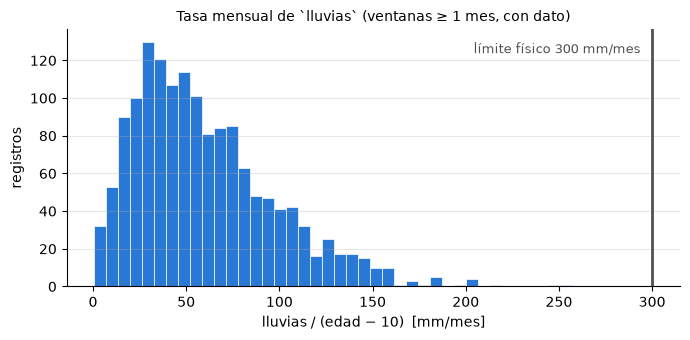

In [8]:
ventana = ipsa["edad"] - 10  # ventana inferida: del mes 10 al corte (ver celda anterior)
tasa = ipsa["lluvias"] / ventana
evaluable = (ventana >= 1) & (ipsa["lluvias"] > 0)
print(f"Filas evaluables (ventana ≥ 1 mes y lluvia con dato): {evaluable.sum()}")
print(f"Tasa mm/mes: mediana {tasa[evaluable].median():.0f}, máx. {tasa[evaluable].max():.0f} | > 300 mm/mes: {(evaluable & (tasa > 300)).sum()}")
print("Lluvias ≥ 900 mm (tope trimestral de regresión, solo como referencia):")
display(ipsa.loc[ipsa["lluvias"] >= 900, COLS].assign(ventana_meses=ventana, mm_mes=tasa.round(0)))
print(f"Ventana < 1 mes con lluvia > 0: {((ventana < 1) & (ipsa['lluvias'] > 0)).sum()} filas (tasa no fiable, como en regresión)")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(tasa[evaluable], bins=40, color=COLORES["serie1"], edgecolor="white", linewidth=0.5)
ax.axvline(300, color=COLORES["tinta"], lw=2)
ax.text(296, ax.get_ylim()[1] * 0.95, "límite físico 300 mm/mes ", ha="right", va="top", fontsize=9, color=COLORES["tinta"])
ax.set_xlabel("lluvias / (edad − 10)  [mm/mes]")
ax.set_ylabel("registros")
ax.set_title("Tasa mensual de `lluvias` (ventanas ≥ 1 mes, con dato)", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_clf_lluvias_tasa.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusión 6: conservar todo (variabilidad natural) + `log1p` en los modelos sensibles a la escala.**
- Con la ventana inferida (del mes 10 al corte, que reproduce la tasa de ~57 mm/mes de `9 -FC`), **ninguna** fila
  supera el límite físico de 300 mm/mes de regresión. El máximo es ~258.
- Los 3 valores ≥ 900 mm (968–1 468) **no** son atípicos: vienen de ventanas de 7.6–9.2 meses (cosechas de 17.6–19.2
  meses), es decir, 105–160 mm/mes. La regla trimestral de 900 no aplica a una ventana más larga, el mismo criterio
  que llevó a no aplicar 180–300 a `Lluvias Ciclo`. Dos de esos valores son de la hacienda 80130, ya señalada en
  regresión.
- **Regla fija registrada para el Pipeline:** recorte a 300 mm/mes × (edad − 10) en ventanas de ≥ 1 mes. Hoy no afecta
  a ninguna fila, pero protege ante datos nuevos. La ventana del mes 10 es una **inferencia** (aproximación
  documentada), no un dato confirmado por el Ingenio.

## 7. Evidencia: `pct_diatrea` rellenada antes de llegar al dataset

> **Decisión: `pct_diatrea` queda excluida de las predictoras por integridad del dato** (
> Variables descartadas). Esta sección no toma ninguna decisión de outliers; solo deja la evidencia que la respalda.

En el bloque 1, `pct_diatrea` figuraba con 0 % de nulos. Al revisar sus extremos aparece una acumulación anómala en
dos valores. Además, en el cruce, HISTORICO no tiene medición de infestación en la mayoría de los registros.

In [9]:
vc = ipsa["pct_diatrea"].value_counts()
for v in (3.2, 4.4):
    vecinos = {round(v + k, 1): int(vc.get(round(v + k, 1), 0)) for k in (-0.2, -0.1, 0.1, 0.2)}
    print(f"{v}: {vc[v]} filas ({vc[v] / len(ipsa):.1%}) | vecinos: {vecinos}")
print("Los dos valores más frecuentes:", vc.head(2).to_dict(), "| siguiente:", vc.iloc[2:3].to_dict())

con_medicion = cruce["%Infest.Diatrea"].notna()
print(f"\nCruce: HISTORICO tiene medición en {con_medicion.sum()} de {len(cruce)} ({con_medicion.mean():.0%}); "
      f"IPSA trae valor en el 100 %")
print("Cobertura de la medición en HISTORICO por año (cruce):",
      cruce.groupby("anio")["%Infest.Diatrea"].apply(lambda s: round(s.notna().mean(), 2)).to_dict())
for v in (3.2, 4.4):
    print(f"  % de filas con valor {v}: con medición {(cruce.loc[con_medicion, 'pct_diatrea'] == v).mean():.1%} "
          f"frente a sin medición {(cruce.loc[~con_medicion, 'pct_diatrea'] == v).mean():.1%}")
cm = cruce[con_medicion]
print(f"  Cuando hay medición, IPSA coincide con HISTORICO (±0.05): {(abs(cm['pct_diatrea'] - cm['%Infest.Diatrea']) < 0.05).mean():.0%}")
print("Filas con 4.4 por año:", ipsa.loc[ipsa["pct_diatrea"] == 4.4, "anio"].value_counts().sort_index().to_dict(),
      "| por grupo de tenencia:", ipsa.loc[ipsa["pct_diatrea"] == 4.4, "grupo_tenencia"].value_counts().sort_index().to_dict())

print("\nCorrelación con los targets según haya medición real (re-chequeo de leakage del bloque 1):")
for t in TARGETS_CLASIFICACION:
    print(f"  {t}: con medición HIST (n={con_medicion.sum()}) {cm['pct_diatrea'].corr(cm[t]):.3f} | "
          f"sin medición (n={(~con_medicion).sum()}) {cruce.loc[~con_medicion, 'pct_diatrea'].corr(cruce.loc[~con_medicion, t]):.3f}")
for t in TARGETS_CLASIFICACION:
    assert abs(cm["pct_diatrea"].corr(cm[t])) < 0.5  # exploratorio: ya no es criterio de inclusión

3.2: 203 filas (9.3%) | vecinos: {3.0: 69, 3.1: 103, 3.3: 32, 3.4: 27}
4.4: 200 filas (9.1%) | vecinos: {4.2: 38, 4.3: 31, 4.5: 26, 4.6: 42}
Los dos valores más frecuentes: {3.2: 203, 4.4: 200} | siguiente: {3.1: 103}

Cruce: HISTORICO tiene medición en 178 de 702 (25%); IPSA trae valor en el 100 %
Cobertura de la medición en HISTORICO por año (cruce): {2017: 0.31, 2018: 0.33, 2019: 0.25, 2020: 0.21, 2021: 0.04}
  % de filas con valor 3.2: con medición 2.2% frente a sin medición 9.2%
  % de filas con valor 4.4: con medición 2.8% frente a sin medición 9.0%
  Cuando hay medición, IPSA coincide con HISTORICO (±0.05): 87%
Filas con 4.4 por año: {2014: 1, 2015: 4, 2016: 7, 2017: 15, 2018: 19, 2019: 55, 2020: 65, 2021: 34} | por grupo de tenencia: {1: 19, 2: 40, 3: 141}

Correlación con los targets según haya medición real (re-chequeo de leakage del bloque 1):
  TCH: con medición HIST (n=178) 0.055 | sin medición (n=524) 0.064
  sacarosa: con medición HIST (n=178) -0.114 | sin medición (n=52

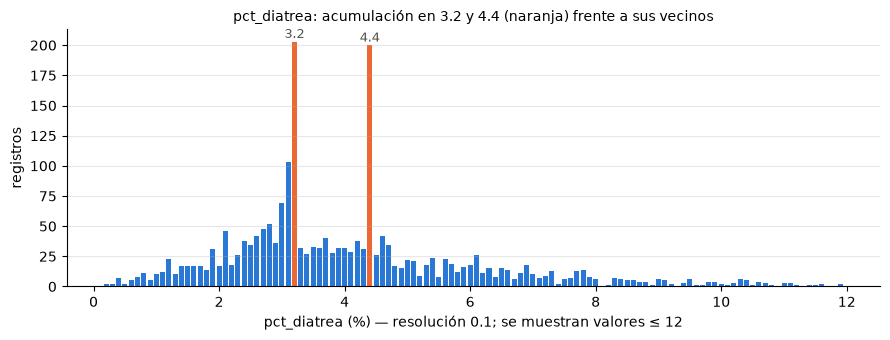

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.5))
conteo = ipsa["pct_diatrea"].round(1).value_counts().sort_index()
conteo = conteo[conteo.index <= 12]
colores = [COLORES["serie2"] if v in (3.2, 4.4) else COLORES["serie1"] for v in conteo.index]
ax.bar(conteo.index, conteo.values, width=0.08, color=colores)
for v in (3.2, 4.4):
    ax.text(v, conteo[v] + 3, f"{v}", ha="center", fontsize=9, color=COLORES["tinta"])
ax.set_xlabel("pct_diatrea (%) — resolución 0.1; se muestran valores ≤ 12")
ax.set_ylabel("registros")
ax.set_title("pct_diatrea: acumulación en 3.2 y 4.4 (naranja) frente a sus vecinos", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_clf_diatrea_acumulacion.png", dpi=150, bbox_inches="tight")
plt.show()

**Lectura de la evidencia:**
1. **3.2 y 4.4 acumulan ~200 filas cada uno (≈ 9 %), entre 3 y 7 veces más que sus vecinos.** En una variable continua
   con resolución de 0.1, esa acumulación es la huella típica de un **valor de relleno** (por defecto o de una media).
2. En el cruce, **HISTORICO solo tiene medición en ~25 % de los registros**, y la cobertura cae a 4 % en 2021. IPSA trae
   valor en todos. Donde los dos tienen dato, coinciden en ~87 %, así que la medición real es la misma variable. La
   diferencia está en que IPSA **completó** los registros sin medición.
3. 3.2 y 4.4 son 3–4 veces más frecuentes en las filas **sin** medición. 4.4 se concentra en 2019–2021 y en el grupo
   de tenencia 3, los mismos años y el mismo grupo con menos registro de campo (como el vacío de lluvia).
4. No se pudo reproducir la regla de relleno: no es la media de los lotes medidos por hacienda, período, año ni grupo.
   Si fue imputación, los valores imputados **no se limitan** a 3.2 y 4.4, y no se pueden identificar uno por uno
   fuera del cruce.
5. **Re-chequeo de leakage:** en el subconjunto con medición real (n = 178), la correlación con los targets sigue
   siendo baja (TCH 0.055; sacarosa −0.114). La baja correlación del bloque 1 **no** se explica por la dilución del
   relleno. El chequeo de leakage se mantiene.

**Consecuencia:** el "0 % de nulos" de `pct_diatrea` (tabla de nulos del bloque 1) no es real. La cobertura efectiva
probablemente es parecida a la de HISTORICO (~25–30 %), donde `%Infest.Diatrea` se **descartó** por tener 73 % de nulos.
Por eso se **excluye** del modelo principal.

## 8. Resumen de decisiones propuestas

| Variable | Rango / casos | Clasificación | Decisión propuesta | Regla fija |
|---|---|---|---|---|
| TCH bajo | 6 y 35 (2 filas < 50) | Evento real (confirmado en HISTORICO: tonelaje coherente; lote sistemáticamente bajo) | **Conservar** | — (la regla de área de regresión no aplica: IPSA no tiene `Area Neta`) |
| TCH alto | máx. 249 | Variabilidad natural (RN: 180–250 no es atípico) | **Conservar** | — |
| sacarosa | 9.2–16.0 | Eventos reales (deterioro poscorte; cosecha postergada) | **Conservar** | — |
| `dosismad` | 1 fila con 9.0 (hueco 2.0–9.0) | Error de captura | **→ NaN + mediana de train** | `dosismad` > 3 → NaN |
| `semsmad` > 20 | 27 filas, máx. 45 | Evento operativo real (cosechas postergadas) | **Conservar** + nodos fijos como en regresión | Coherencia: meses de madurante ≤ edad (0 violaciones) |
| `edad` | 10.3–21.1 | Variabilidad natural | **Conservar** | Tope de 36 de regresión (0 filas lo superan) |
| `cortes` | 1–14 | Manejo legítimo (RN > 20) | **Conservar** | — |
| `lluvias` | máx. 1 468 mm; ≤ 258 mm/mes | Variabilidad natural (ventanas largas) | **Conservar** + `log1p` | Recorte a 300 mm/mes × (edad − 10) si la ventana es ≥ 1 mes (0 filas hoy) |

`pct_diatrea` no se evalúa como predictora: está excluida por integridad del dato (ver §7).

Todo aplica solo a CC01-1940 madurada con BONUS 250 EC y cosechada a máquina.